# Prepares observational datasets to be used for timeseries, then SST-BGC var relationships

#### (for now the timeseries are trimmed from 2003 to 2021, but will update obs datasets to extend further)

In [2]:
%matplotlib inline
import os
from glob import glob
from collections import OrderedDict
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import gc
import pandas as pd

import xesmf #for regridding
xr.set_options(keep_attrs=True)
import regionmask #for generating 1° ocean mask

### Make a standard 1° ones masks for masking, etc. (one for lons -180 to 180 and one for lons 0 to 360)

In [3]:
ones = np.full((180,360),1,dtype=int)
ones = xr.DataArray(ones,dims=('lat','lon'))
ones['lat'] = np.arange(-89.5, 90, 1)
ones['lon'] = np.arange(-179.5, 180, 1)

In [4]:
ones2 = np.full((180,360),1,dtype=int)
ones2 = xr.DataArray(ones2,dims=('lat','lon'))
ones2['lat'] = np.arange(-89.5, 90, 1)
ones2['lon'] = np.arange(0.5, 360, 1)

In [5]:
# Define the 1-degree latitude and longitude points
lon = np.arange(-179.5, 180, 1)
lat = np.arange(-89.5, 90, 1)

time = pd.date_range(start="2002-07-01", end="2022-01-01",freq="ME")

# Create the land mask using Natural Earth data (default resolution is 1:110m)
# The mask will be boolean (True for land) on the specified grid
land_mask = regionmask.defined_regions.natural_earth_v5_1_2.land_110.mask(lon, lat)
land_mask = land_mask.where(land_mask==0, other=1)

In [6]:
time

DatetimeIndex(['2002-07-31', '2002-08-31', '2002-09-30', '2002-10-31',
               '2002-11-30', '2002-12-31', '2003-01-31', '2003-02-28',
               '2003-03-31', '2003-04-30',
               ...
               '2021-03-31', '2021-04-30', '2021-05-31', '2021-06-30',
               '2021-07-31', '2021-08-31', '2021-09-30', '2021-10-31',
               '2021-11-30', '2021-12-31'],
              dtype='datetime64[ns]', length=234, freq='ME')

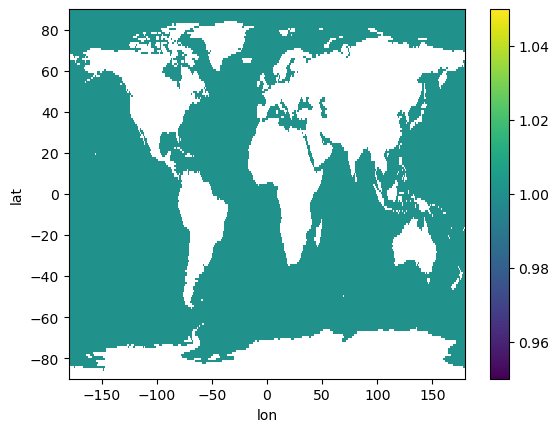

In [7]:
ones = ones.where(land_mask==1)
ones.plot()

### Create an empty dataset - will put the obs data at regular 1° in it

In [8]:
ds = xr.Dataset()

ds = ds.assign_coords({"lon": lon})
ds = ds.assign_coords({"lat": lat})
ds = ds.assign_coords({"time": time})

# Read in monthly observational data  and then regrid to 1°

## Chlorophyll  from MODIS

In [9]:
from pathlib import Path

# Define the target directory path
path = "/glade/work/kristenk/satellite_data/monthlyChl/"
dir_path = Path("/glade/work/kristenk/satellite_data/monthlyChl")

# Filter and list only files
files = [f.name for f in dir_path.iterdir() if f.is_file()]
files = sorted(files)
#print(files)

In [10]:
tlen=len(files)

In [11]:
ny = 2160
nx = 4320

modis_chl = np.full((tlen,ny,nx),-9999.)

t = 0
for file in files:
    ds_tmp = xr.open_dataset(path + file)
    modis_chl[t,:,:] = np.flipud(ds_tmp.chlor_a.values)
    t = t + 1

chl_attrs = ds_tmp.chlor_a.attrs

modis_chl = xr.DataArray(modis_chl, dims=('time','lat','lon'))

ds_sat_chl = xr.Dataset()
ds_sat_chl['chl'] = modis_chl

lat_data = np.arange(-90+1/24,90,1/12)
lon_data = np.arange(-180+1/24,180,1/12)

ds_sat_chl['lat'] = lat_data
ds_sat_chl['lon'] = lon_data
ds_sat_chl.chl.attrs = chl_attrs

In [12]:
ds_sat_chl

<xarray.Dataset> Size: 17GB
Dimensions:  (time: 234, lat: 2160, lon: 4320)
Coordinates:
  * lat      (lat) float64 17kB -89.96 -89.88 -89.79 ... 89.79 89.87 89.96
  * lon      (lon) float64 35kB -180.0 -179.9 -179.8 ... 179.8 179.9 180.0
Dimensions without coordinates: time
Data variables:
    chl      (time, lat, lon) float64 17GB nan nan nan nan ... nan nan nan nan

#### Regrid Chl to regular 1° grid

In [13]:
def regrid_chl(ds_in, varname):
    
    lon = ds.lon.values
    lat = ds.lat.values
    
    ds_out = xr.Dataset({"lon": (["lon"], lon),"lat": (["lat"], lat)})

    #ds_in = ds_in.assign_coords(lat=grid_in.lat, lat_b=grid_in.lat_b, lon=grid_in.lon, lon_b=grid_in.lon_b)
    #ds_in = ds_in.assign_coords(lat=ds.lat, lon=ds.lon)
    
    def regrid_tracer(varname, ds_in, ds_out, method='bilinear'):
    
        regrid = xesmf.Regridder(
            ds_in,
            ds_out,
            method=method,
            periodic=True,
        )
        fld_out = regrid(ds_in[varname])
        return fld_out

    var_1x1 = regrid_tracer(varname, ds_in, ds_out)

    return(var_1x1)

In [14]:
chl = regrid_chl(ds_sat_chl, 'chl')
chl.attrs = chl_attrs

In [15]:
# 1. Release file handles
ds_sat_chl.close()

# 2. Delete the variable references
del ds_sat_chl

# 3. Force garbage collection to free RAM
gc.collect()

11762

### Add the chlorophyll to the dataset

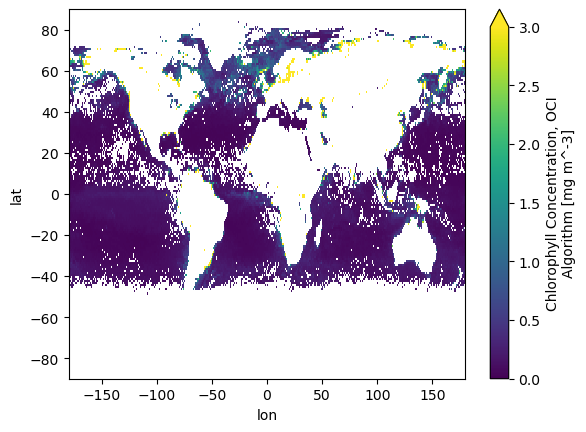

In [16]:
chl.isel(time=0).plot(vmin=0,vmax=3)

In [17]:
ds['Chl'] = chl.transpose("lat", "lon", "time")

ds

<xarray.Dataset> Size: 121MB
Dimensions:  (lon: 360, lat: 180, time: 234)
Coordinates:
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * time     (time) datetime64[ns] 2kB 2002-07-31 2002-08-31 ... 2021-12-31
Data variables:
    Chl      (lat, lon, time) float64 121MB nan nan nan nan ... nan nan nan nan

In [18]:
ds.time

<xarray.DataArray 'time' (time: 234)> Size: 2kB
array(['2002-07-31T00:00:00.000000000', '2002-08-31T00:00:00.000000000',
       '2002-09-30T00:00:00.000000000', ..., '2021-10-31T00:00:00.000000000',
       '2021-11-30T00:00:00.000000000', '2021-12-31T00:00:00.000000000'],
      shape=(234,), dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 2kB 2002-07-31 2002-08-31 ... 2021-12-31

## Sea ice observations from Climate Data Record

In [19]:
file1 = '/glade/campaign/cgd/cas/observations/siconc/seaice_conc_monthly_nh_NOAA_NSIDC_CDR.v06r00.197811-202602.nc'
file2 = '/glade/campaign/cgd/cas/observations/siconc/seaice_conc_monthly_sh_NOAA_NSIDC_CDR.v06r00.197811-202602.nc'

nh_ice = xr.open_dataset(file1)
sh_ice = xr.open_dataset(file2)

### Trim the sea ice data to the same months/years as the Chl data

In [20]:
sh_ice = sh_ice.isel(time=slice(284,518))
nh_ice = nh_ice.isel(time=slice(284,518))

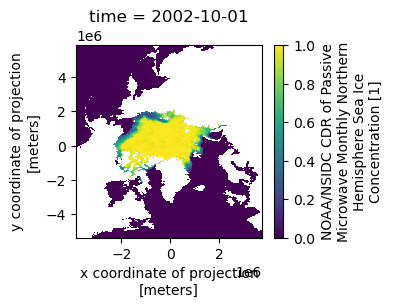

In [21]:
nh_ice.SIC.isel(time=3).plot(figsize=(3,2.5))

In [22]:
ice_attrs = nh_ice.SIC.attrs
ice_attrs['long_name'] = 'monthly averaged CDR SIC'

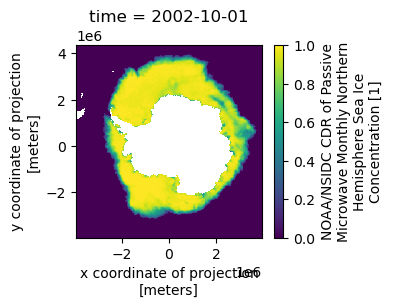

In [23]:
sh_ice.SIC.isel(time=3).plot(figsize=(3,2.5))

In [24]:
def regrid_ice(ds_in, varname):
    
    lon = np.arange(0.5, 360, 1)
    lat = np.arange(-89.5, 90, 1)
    
    ds_out = xr.Dataset({"lon": (["lon"], lon),"lat": (["lat"], lat)})

    def regrid_tracer(varname, ds_in, ds_out, method='bilinear'):
    
        regrid = xesmf.Regridder(
            ds_in,
            ds_out,
            method=method,
            #periodic=True,
        )
        fld_out = regrid(ds_in[varname])
        return fld_out

    var_1x1 = regrid_tracer(varname, ds_in, ds_out)

    return(var_1x1)

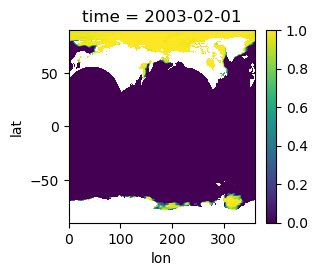

In [25]:
tmp = regrid_ice(sh_ice, 'SIC')
tmp2 = regrid_ice(nh_ice, 'SIC')
ice_tmp = tmp + tmp2

ice_tmp = ice_tmp.where(ones2==1)
ice_tmp.isel(time=7).plot(figsize=(3,2.5))

In [26]:
part1 = ice_tmp.where(ice_tmp>=0).sel(lon=slice(180,360))
part2 = ice_tmp.where(ice_tmp>=0).sel(lon=slice(0,180))

In [27]:
tlen = len(sh_ice.time)

ice = np.full((tlen,180,360),1,dtype='float32')

for ts in np.arange(0,tlen,1):

    tmp = np.full((180,360),1,dtype='float32')
    tmp[:,0:180] = part1.isel(time=ts).values
    tmp[:,180:360] = part2.isel(time=ts).values
    ice[ts,:,:] = tmp
    
ice = xr.DataArray(ice,dims=('time','lat','lon'))
ice = ice.where(ones>=0, other=np.nan).where(ice>=0)

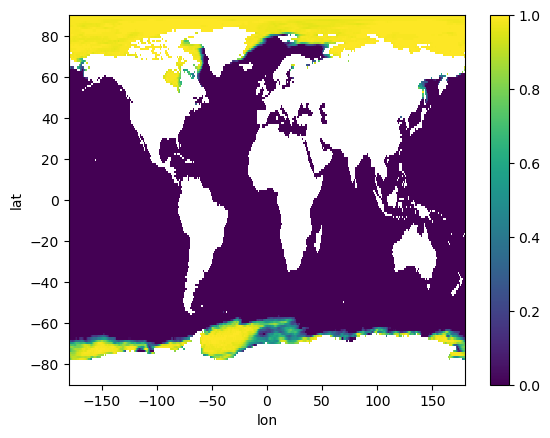

In [28]:
ice.isel(time=5).plot()

In [29]:
ice.attrs = ice_attrs

In [30]:
ds['ice'] = ice.transpose("lat", "lon", "time")

ds

<xarray.Dataset> Size: 182MB
Dimensions:  (lon: 360, lat: 180, time: 234)
Coordinates:
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * time     (time) datetime64[ns] 2kB 2002-07-31 2002-08-31 ... 2021-12-31
Data variables:
    Chl      (lat, lon, time) float64 121MB nan nan nan nan ... nan nan nan nan
    ice      (lat, lon, time) float32 61MB nan nan nan nan ... 1.0 1.0 1.0

## SST data

In [31]:
ny = 2160
nx = 4320

files = sorted(glob('/glade/work/kristenk/satellite_data/new_monthlySST/AQUA_MODIS.????????_????????.L3m.MO.SST.sst.9km.nc'))
tlen=len(files)

modis_sst = np.full((tlen,ny,nx),-9999.)

t = 0
for file in files:
    ds_tmp = xr.open_dataset(file)
    modis_sst[t,:,:] = np.flipud(ds_tmp.sst.values)
    t = t + 1
sst_attrs = ds_tmp.sst.attrs
modis_sst = xr.DataArray(modis_sst, dims=('time','lat','lon'))

ds_sat_sst = xr.Dataset()
ds_sat_sst['sst'] = modis_sst

lat_data = np.arange(-90+1/24,90,1/12)
lon_data = np.arange(-180+1/24,180,1/12)

ds_sat_sst['lat'] = lat_data
ds_sat_sst['lon'] = lon_data
ds_sat_sst.sst.attrs = sst_attrs

In [32]:
#files

In [33]:
ds_sat_sst['time'] = pd.date_range(start="2002-08-01", end="2024-06-01",freq="ME")

In [34]:
def regrid_sst(ds_in, varname):
    
    lon = ds.lon.values
    lat = ds.lat.values
    
    ds_out = xr.Dataset({"lon": (["lon"], lon),"lat": (["lat"], lat)})

    def regrid_tracer(varname, ds_in, ds_out, method='bilinear'):
    
        regrid = xesmf.Regridder(
            ds_in,
            ds_out,
            method=method,
            periodic=True,
        )
        fld_out = regrid(ds_in[varname])
        return fld_out

    var_1x1 = regrid_tracer(varname, ds_in, ds_out)

    return(var_1x1)

In [35]:
sst = regrid_sst(ds_sat_sst, 'sst')
sst.attrs = sst_attrs

In [36]:
sst.time

<xarray.DataArray 'time' (time: 262)> Size: 2kB
array(['2002-08-31T00:00:00.000000000', '2002-09-30T00:00:00.000000000',
       '2002-10-31T00:00:00.000000000', ..., '2024-03-31T00:00:00.000000000',
       '2024-04-30T00:00:00.000000000', '2024-05-31T00:00:00.000000000'],
      shape=(262,), dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 2kB 2002-08-31 2002-09-30 ... 2024-05-31

### SST data only starts in Aug 2002, so trim the first time slice off the master dataset (which starts in Jul 2002)

In [37]:
ds = ds.isel(time=slice(1,234))

### Now trim SST data so it stops at Dec 2021

In [38]:
sst = sst.isel(time=slice(0,233))
#sst

### Now add it to the master ds

In [39]:
ds['SST'] = sst.transpose("lat", "lon", "time")

### Now make seasonal means: DJF, MAM, JJA, SON

In [40]:
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
#starting with Jan, list of days in each month
days_per_month = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

In [41]:
ds_DJF = xr.Dataset()
ds_MAM = xr.Dataset()
ds_JJA = xr.Dataset()
ds_SON = xr.Dataset()

In [42]:
ds.time[4]

<xarray.DataArray 'time' ()> Size: 8B
array('2002-12-31T00:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 8B 2002-12-31

### DJF means (the D is from the year before, so Dec 2002 to Feb 2003 has the year 2003)

In [43]:
#%%time

years = np.arange(2003,2021+1,1)

tlen = len(years)
xlen = len(ds.lon)
ylen = len(ds.lat)

vars = ['Chl','ice','SST']

for var in vars:

    DJF_mean = np.zeros([ylen, xlen, tlen])

    for year in np.arange(0,tlen,1):

        #get december for this year (data starts in Aug 2002 so index 4 is december)
        st_mon = year*12 + 4
        #print(year)
    
        i=0
        for month in [12,1,2]:
    
            if(month == 12):
                summing = ds[var].isel(time=st_mon) * days_per_month[month-1]
                tot_days = days_per_month[month-1]
            else:
                summing = summing + ds[var].isel(time=st_mon+i) * days_per_month[month-1]
                tot_days = tot_days + days_per_month[month-1]
    
            i = i + 1
    
        DJF_mean[:,:,year] = (summing/tot_days).compute()
    
    DJF_mean = xr.DataArray(DJF_mean,dims=('lat','lon','time'))
    
    ds_DJF[var] = DJF_mean
  

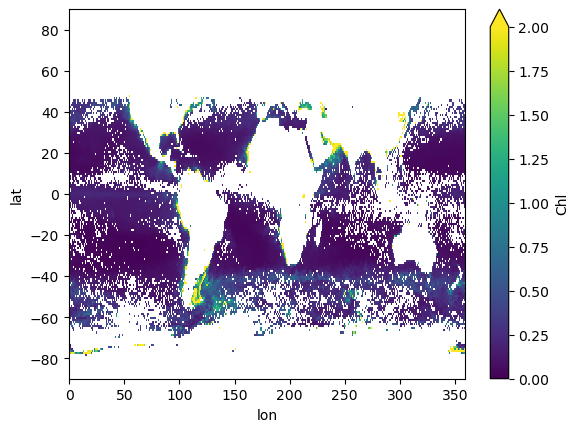

In [59]:
ds_DJF.Chl.isel(time=18).plot(vmin=0,vmax=2)

### MAM

In [45]:
ds.time[7].values

np.datetime64('2003-03-31T00:00:00.000000000')

In [46]:
#%%time

years = np.arange(2003,2021+1,1)

tlen = len(years)
xlen = len(ds.lon)
ylen = len(ds.lat)

vars = ['Chl','ice','SST']

for var in vars:

    MAM_mean = np.zeros([ylen, xlen, tlen])

    for year in np.arange(0,tlen,1):

        #get march for this year (data starts in Aug 2002 so index 7 is march)
        st_mon = year*12 + 7
        #print(year)
    
        i=0
        for month in [3,4,5]:
    
            if(month == 3):
                summing = ds[var].isel(time=st_mon) * days_per_month[month-1]
                tot_days = days_per_month[month-1]
            else:
                summing = summing + ds[var].isel(time=st_mon+i) * days_per_month[month-1]
                tot_days = tot_days + days_per_month[month-1]
    
            i = i + 1
    
        MAM_mean[:,:,year] = (summing/tot_days).compute()
    
    MAM_mean = xr.DataArray(MAM_mean,dims=('lat','lon','time'))
    
    ds_MAM[var] = MAM_mean
  

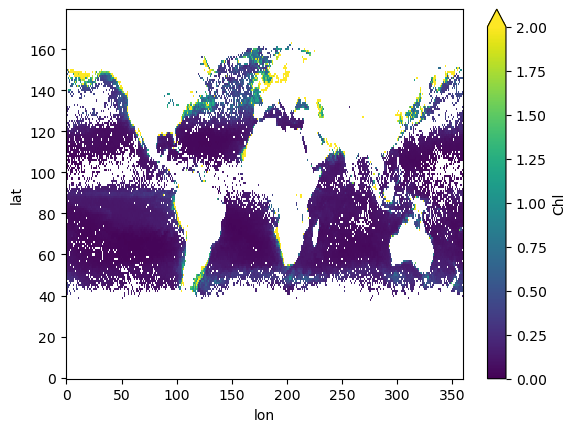

In [47]:
ds_MAM.Chl.isel(time=0).plot(vmin=0,vmax=2)

### JJA

In [48]:
ds.time[10].values

np.datetime64('2003-06-30T00:00:00.000000000')

In [49]:
#%%time

years = np.arange(2003,2021+1,1)

tlen = len(years)
xlen = len(ds.lon)
ylen = len(ds.lat)

vars = ['Chl','ice','SST']

for var in vars:

    JJA_mean = np.zeros([ylen, xlen, tlen])

    for year in np.arange(0,tlen,1):

        #get june for this year (data starts in Aug 2002 so index 10 is june)
        st_mon = year*12 + 10
        #print(year)
    
        i=0
        for month in [6,7,8]:
    
            if(month == 6):
                summing = ds[var].isel(time=st_mon) * days_per_month[month-1]
                tot_days = days_per_month[month-1]
            else:
                summing = summing + ds[var].isel(time=st_mon+i) * days_per_month[month-1]
                tot_days = tot_days + days_per_month[month-1]
    
            i = i + 1
    
        JJA_mean[:,:,year] = (summing/tot_days).compute()
    
    JJA_mean = xr.DataArray(JJA_mean,dims=('lat','lon','time'))
    
    ds_JJA[var] = JJA_mean
  

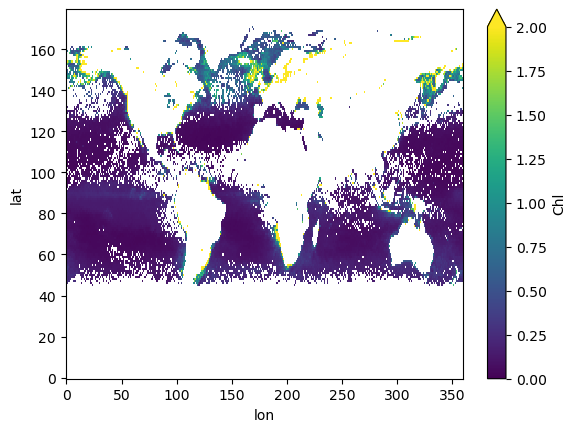

In [50]:
ds_JJA.Chl.isel(time=0).plot(vmin=0,vmax=2)

### SON

In [51]:
ds.time[13].values

np.datetime64('2003-09-30T00:00:00.000000000')

In [52]:
#%%time

years = np.arange(2003,2021+1,1)

tlen = len(years)
xlen = len(ds.lon)
ylen = len(ds.lat)

vars = ['Chl','ice','SST']

for var in vars:

    SON_mean = np.zeros([ylen, xlen, tlen])

    for year in np.arange(0,tlen,1):

        #get sept for this year 2003 (data starts in Aug 2002 so index 13 is sept)
        st_mon = year*12 + 13
        #print(year)
    
        i=0
        for month in [9,10,11]:
    
            if(month == 9):
                summing = ds[var].isel(time=st_mon) * days_per_month[month-1]
                tot_days = days_per_month[month-1]
            else:
                summing = summing + ds[var].isel(time=st_mon+i) * days_per_month[month-1]
                tot_days = tot_days + days_per_month[month-1]
    
            i = i + 1
    
        SON_mean[:,:,year] = (summing/tot_days).compute()
    
    SON_mean = xr.DataArray(SON_mean,dims=('lat','lon','time'))
    
    ds_SON[var] = SON_mean
  

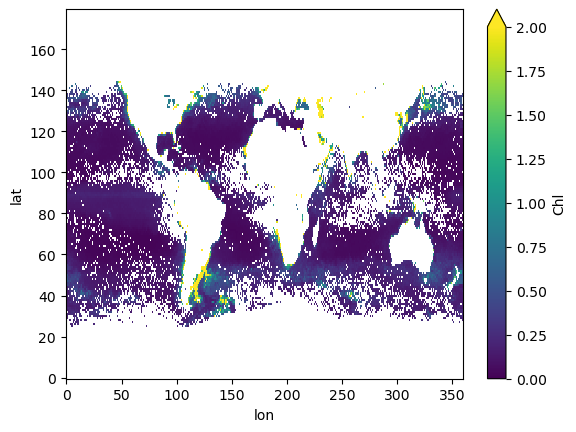

In [53]:
ds_SON.Chl.isel(time=0).plot(vmin=0,vmax=2)

In [54]:
ones.lat

<xarray.DataArray 'lat' (lat: 180)> Size: 1kB
array([-89.5, -88.5, -87.5, -86.5, -85.5, -84.5, -83.5, -82.5, -81.5, -80.5,
       -79.5, -78.5, -77.5, -76.5, -75.5, -74.5, -73.5, -72.5, -71.5, -70.5,
       -69.5, -68.5, -67.5, -66.5, -65.5, -64.5, -63.5, -62.5, -61.5, -60.5,
       -59.5, -58.5, -57.5, -56.5, -55.5, -54.5, -53.5, -52.5, -51.5, -50.5,
       -49.5, -48.5, -47.5, -46.5, -45.5, -44.5, -43.5, -42.5, -41.5, -40.5,
       -39.5, -38.5, -37.5, -36.5, -35.5, -34.5, -33.5, -32.5, -31.5, -30.5,
       -29.5, -28.5, -27.5, -26.5, -25.5, -24.5, -23.5, -22.5, -21.5, -20.5,
       -19.5, -18.5, -17.5, -16.5, -15.5, -14.5, -13.5, -12.5, -11.5, -10.5,
        -9.5,  -8.5,  -7.5,  -6.5,  -5.5,  -4.5,  -3.5,  -2.5,  -1.5,  -0.5,
         0.5,   1.5,   2.5,   3.5,   4.5,   5.5,   6.5,   7.5,   8.5,   9.5,
        10.5,  11.5,  12.5,  13.5,  14.5,  15.5,  16.5,  17.5,  18.5,  19.5,
        20.5,  21.5,  22.5,  23.5,  24.5,  25.5,  26.5,  27.5,  28.5,  29.5,
        30.5,  31.5,  32.5,  33.5,  34.5,  35.5,  36.5,  37.5,  38.5,  39.5,
        40.5,  41.5,  42.5,  43.5,  44.5,  45.5,  46.5,  47.5,  48.5,  49.5,
        50.5,  51.5,  52.5,  53.5,  54.5,  55.5,  56.5,  57.5,  58.5,  59.5,
        60.5,  61.5,  62.5,  63.5,  64.5,  65.5,  66.5,  67.5,  68.5,  69.5,
        70.5,  71.5,  72.5,  73.5,  74.5,  75.5,  76.5,  77.5,  78.5,  79.5,
        80.5,  81.5,  82.5,  83.5,  84.5,  85.5,  86.5,  87.5,  88.5,  89.5])
Coordinates:
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5

### Add coords

In [55]:
ds_SON['lat'] = ones.lat
ds_JJA['lat'] = ones.lat
ds_MAM['lat'] = ones.lat
ds_DJF['lat'] = ones.lat

In [73]:
ds_SON['lon'] = ones.lon
ds_JJA['lon'] = ones.lon
ds_MAM['lon'] = ones.lon
ds_DJF['lon'] = ones.lon

In [57]:
ds_DJF['time']

<xarray.DataArray 'time' (time: 19)> Size: 152B
[19 values with dtype=int64]
Dimensions without coordinates: time

In [58]:
ds_JJA['time']

<xarray.DataArray 'time' (time: 19)> Size: 152B
array([2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014,
       2015, 2016, 2017, 2018, 2019, 2020, 2021])
Coordinates:
  * time     (time) int64 152B 2003 2004 2005 2006 2007 ... 2018 2019 2020 2021

In [60]:
ds_SON['time'] = years
ds_MAM['time'] = years
ds_JJA['time'] = years
ds_DJF['time'] = years

## Looks good, now let's write out netcdfs

In [62]:
output_dir = '/glade/derecho/scratch/kristenk/INDEX_BGC_work'

ds_DJF.to_netcdf(output_dir + '/dsDJF_obs_2003to2021.nc', mode='w')
ds_MAM.to_netcdf(output_dir + '/dsMAM_obs_2003to2021.nc', mode='w')
ds_JJA.to_netcdf(output_dir + '/dsJJA_obs_2003to2021.nc', mode='w')
ds_SON.to_netcdf(output_dir + '/dsSON_obs_2003to2021.nc', mode='w')